# Projet 5 — Maintenance prédictive d'une machine-outil (ML + logique floue)

**Module :** Techniques avancées pour systèmes intelligents — 3ᵉ année Génie Mécatronique, ENISo — 2026/2027
**Binôme :** Ahmed Daouahi — Mohamed Bennour
**Jeu de données :** AI4I 2020 Predictive Maintenance Dataset (UCI / Kaggle), 10 000 mesures d'une fraiseuse

**Objectif.** Prédire la panne de la machine à partir des mesures du procédé (modèle ML), puis traduire la probabilité de panne, l'usure de l'outil et l'échauffement en une **priorité de maintenance** lisible par un opérateur (système flou).

**Plan du notebook**
1. Chargement et découverte des données
2. Préparation (variables physiques, fuite de données, découpage)
3. Reproduction de l'approche standard des notebooks publics (référence)
4. Comparaison des modèles par validation croisée (baseline, régression logistique, Random Forest, XGBoost)
5. Choix du seuil de décision
6. Évaluation finale sur le jeu de test, analyse des cas d'échec, temps d'inférence
7. Système flou : priorité de maintenance
8. Conclusion

## 0. Installation et imports

In [1]:
import importlib, subprocess, sys
for paquet, module in [('scikit-fuzzy', 'skfuzzy'), ('xgboost', 'xgboost')]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquet], check=True)

In [2]:
import glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

import skfuzzy as fuzz
from skfuzzy import control as ctrl

warnings.filterwarnings('ignore')
GRAINE = 42   # graine aléatoire fixe : les résultats sont reproductibles
np.random.seed(GRAINE)

## 1. Chargement des données

Le fichier contient 10 000 mesures d'une fraiseuse : type de produit (qualité L, M, H), températures de l'air et du procédé, vitesse de rotation, couple, usure de l'outil, et si la machine est tombée en panne (avec le type de panne).

Le notebook cherche le fichier dans les données Kaggle (`/kaggle/input`) ou dans le dossier `data/` du dépôt.

In [3]:
fichiers = (glob.glob('/kaggle/input/**/ai4i2020.csv', recursive=True)
            + glob.glob('data/ai4i2020.csv') + glob.glob('ai4i2020.csv'))
if not fichiers:
    raise FileNotFoundError("ai4i2020.csv introuvable : ajoutez le jeu « AI4I 2020 » (Add Input sur Kaggle) "
                            "ou placez le fichier dans le dossier data/.")
df = pd.read_csv(fichiers[0], encoding='utf-8-sig')
print("Fichier lu :", fichiers[0])

# Noms de colonnes plus courts (recherche par mot-clé pour éviter les erreurs de frappe)
def renommer(col):
    c = col.lower()
    if 'air' in c:             return 'temp_air'       # K
    if 'process' in c:         return 'temp_process'   # K
    if 'rotational' in c:      return 'vitesse'        # tr/min
    if 'torque' in c:          return 'couple'         # Nm
    if 'wear' in c:            return 'usure'          # min
    if 'machine failure' in c: return 'panne'          # 0 / 1
    return col
df = df.rename(columns=renommer)
print(df.shape)
df.head()

Fichier lu : data/ai4i2020.csv
(10000, 14)


,UDI,Product ID,Type,temp_air,temp_process,vitesse,couple,usure,panne,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Découverte des données

In [4]:
print("Valeurs manquantes :", int(df.isna().sum().sum()))
print(f"Taux de panne : {df['panne'].mean()*100:.2f} %  ({int(df['panne'].sum())} pannes sur {len(df)})")
print()
print("Nombre de pannes par type (TWF usure outil, HDF dissipation thermique, PWF puissance, OSF surcharge, RNF aléatoire) :")
print(df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum())
df[['temp_air', 'temp_process', 'vitesse', 'couple', 'usure']].describe().round(1)

Valeurs manquantes : 0
Taux de panne : 3.39 %  (339 pannes sur 10000)

Nombre de pannes par type (TWF usure outil, HDF dissipation thermique, PWF puissance, OSF surcharge, RNF aléatoire) :
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64


,temp_air,temp_process,vitesse,couple,usure
count,10000.0,10000.0,10000.0,10000.0,10000.0
mean,300.0,310.0,1538.8,40.0,108.0
std,2.0,1.5,179.3,10.0,63.7
min,295.3,305.7,1168.0,3.8,0.0
25%,298.3,308.8,1423.0,33.2,53.0
50%,300.1,310.1,1503.0,40.1,108.0
75%,301.5,311.1,1612.0,46.8,162.0
max,304.5,313.8,2886.0,76.6,253.0


**À retenir.** Le jeu est propre (aucune valeur manquante) mais très **déséquilibré** : 339 pannes sur 10 000 mesures (3,4 %). Un modèle qui répond toujours « pas de panne » aurait donc une accuracy d'environ 97 % tout en étant inutile. C'est pour cela que l'accuracy ne sera pas notre métrique principale.

Les pannes se répartissent en cinq modes : dissipation thermique (HDF, 115), surcharge (OSF, 98), puissance (PWF, 95), usure de l'outil (TWF, 46) et pannes aléatoires (RNF, 19). Une même mesure peut avoir plusieurs modes, et quelques pannes n'ont aucun mode renseigné (bruit d'étiquetage du jeu de données).

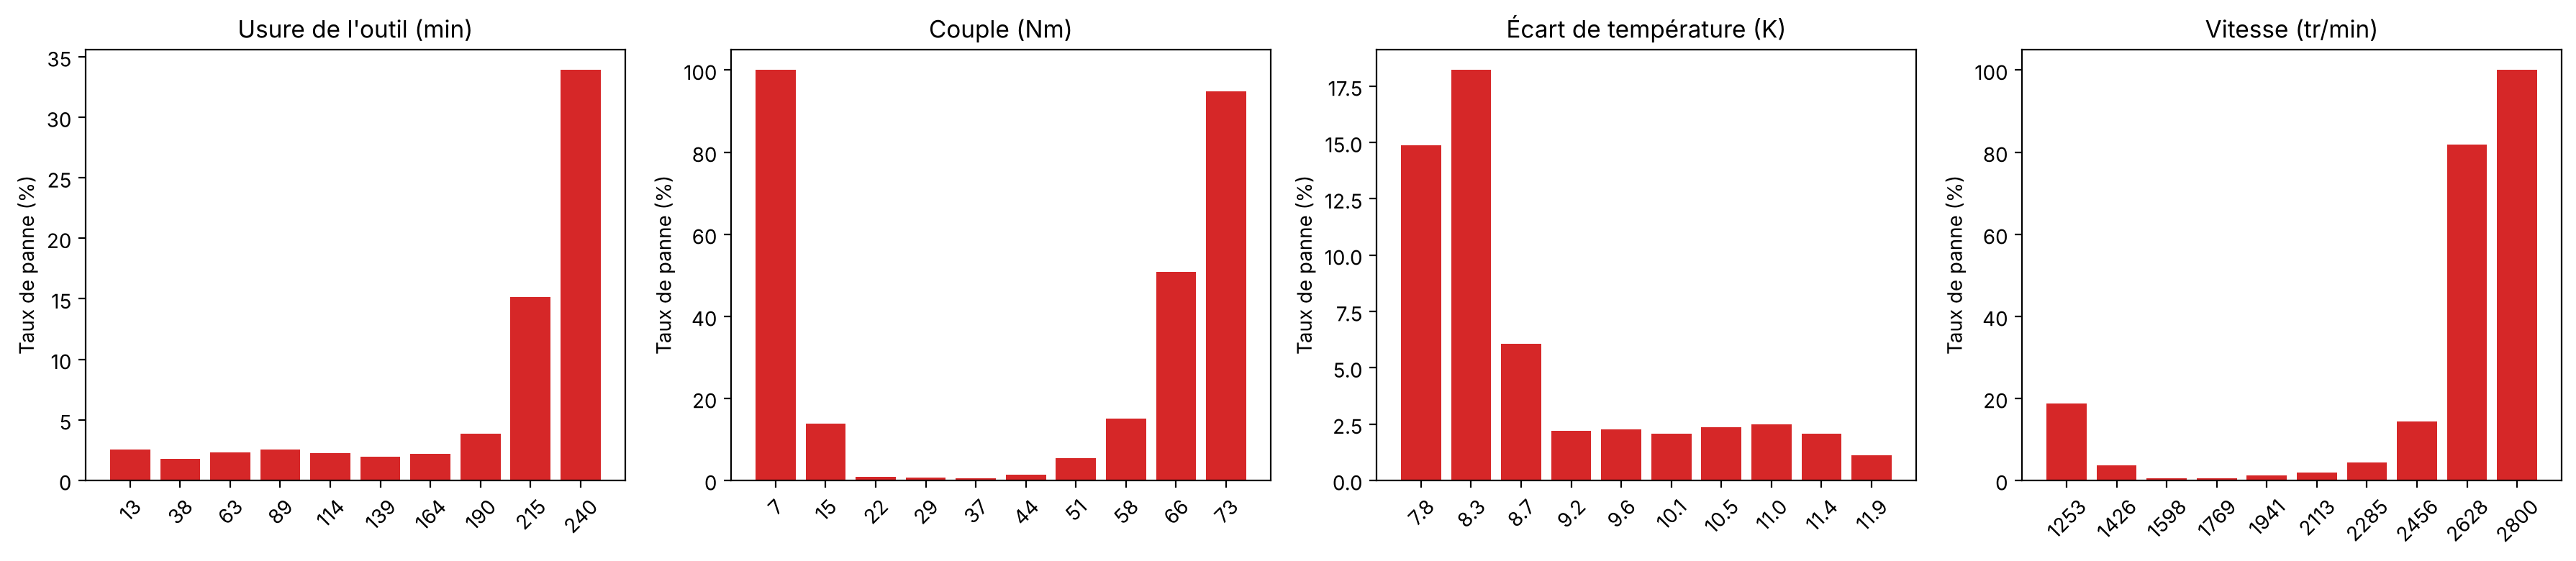

In [5]:
# Variables construites avec du bon sens mécanique
df['ecart_temp'] = df['temp_process'] - df['temp_air']             # K : écart entre le procédé et l'air ambiant
df['puissance']  = df['couple'] * df['vitesse'] * 2 * np.pi / 60   # W : puissance mécanique = couple x vitesse angulaire
df['surcharge']  = df['usure'] * df['couple']                      # min.Nm : outil usé ET fort couple

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col, titre in zip(axes, ['usure', 'couple', 'ecart_temp', 'vitesse'],
                          ["Usure de l'outil (min)", 'Couple (Nm)', 'Écart de température (K)', 'Vitesse (tr/min)']):
    classes = pd.cut(df[col], 10)
    taux = df.groupby(classes, observed=True)['panne'].mean() * 100
    ax.bar(range(len(taux)), taux.values, color='tab:red')
    ax.set_xticks(range(len(taux)))
    ax.set_xticklabels([f"{i.mid:.1f}" if col == 'ecart_temp' else f"{i.mid:.0f}" for i in taux.index], rotation=45)
    ax.set_title(titre); ax.set_ylabel('Taux de panne (%)')
plt.tight_layout(); plt.show()

**Lecture des graphiques (taux de panne par tranche de valeur).**
- **Usure de l'outil** : le taux de panne reste autour de 2 % jusqu'à environ 190 min, puis explose (15 % vers 215 min, 34 % au-delà de 230 min). C'est la signature de l'usure : l'outil devient fragile en fin de vie.
- **Couple** : relation en « U ». Un couple très faible (moins de 15 Nm, associé aux très grandes vitesses) ou très fort (plus de 60 Nm) conduit presque toujours à la panne : ce sont les pannes de **puissance** (puissance mécanique trop faible ou trop forte).
- **Écart de température** : le taux de panne est élevé quand l'écart est **faible** (15 à 18 % en dessous de 8,5 K) et retombe à environ 2 % au-delà de 9 K. Physiquement, un faible écart entre le procédé et l'air ambiant signifie que la chaleur de coupe s'évacue mal. Le risque thermique augmente donc quand l'écart **diminue**, ce qui justifie la définition `échauffement = 12 − écart` du système flou (partie 7).
- **Vitesse** : les vitesses extrêmes sont dangereuses. Très basse vitesse (vers 1 250 tr/min) : pannes thermiques. Très haute vitesse (plus de 2 400 tr/min) : couple très faible et donc puissance insuffisante.

Aucune variable n'explique seule les pannes : chaque mode de panne correspond à une **combinaison** de grandeurs. D'où l'intérêt de construire les variables `puissance` (couple × vitesse angulaire) et `surcharge` (usure × couple).

In [6]:
# Vérification physique : dans quelles conditions apparaissent les pannes thermiques (HDF) ?
print("Pannes HDF — écart de température et vitesse :")
print(df.loc[df['HDF'] == 1, ['ecart_temp', 'vitesse']].describe().round(2).loc[['min', 'mean', 'max']])
print()
print("Pannes TWF — usure de l'outil :")
print(df.loc[df['TWF'] == 1, 'usure'].describe().round(0).loc[['min', 'mean', 'max']])

Pannes HDF — écart de température et vitesse :
      ecart_temp  vitesse
min         7.60  1212.00
mean        8.23  1337.26
max         8.60  1379.00

Pannes TWF — usure de l'outil :
min     198.0
mean    216.0
max     253.0
Name: usure, dtype: float64


**Vérification de la définition de l'échauffement.** Toutes les pannes HDF ont un écart de température entre 7,6 et 8,6 K et une vitesse inférieure à 1 380 tr/min : la panne thermique apparaît quand la chaleur s'évacue mal **et** que la broche tourne lentement. Avec `échauffement = 12 − écart`, la zone dangereuse correspond à un échauffement supérieur à 3,4 K. Le terme « élevé » de l'échauffement (partie 7) est centré sur cette transition.

Les pannes TWF apparaissent toutes entre 198 et 253 min d'usure : c'est la zone que le terme « usure élevée » du système flou doit couvrir.

## 3. Préparation

**Attention à la fuite de données.** Les colonnes TWF, HDF, PWF, OSF et RNF décrivent le type de panne : elles ne sont connues qu'**après** la panne. Si on les donne au modèle, il « triche » (il lit la réponse). On les retire des entrées, ainsi que les identifiants `UDI` et `Product ID` qui n'ont pas de sens physique.

On garde 20 % des données comme **jeu de test**, qui n'est utilisé qu'une seule fois, à la fin. Tous les réglages (choix du modèle, du seuil) se font sur les 80 % restants, par validation croisée.

In [7]:
df['type_num'] = df['Type'].map({'L': 0, 'M': 1, 'H': 2})   # qualité du produit : basse, moyenne, haute

entrees_brutes = ['type_num', 'temp_air', 'temp_process', 'vitesse', 'couple', 'usure']
entrees = entrees_brutes + ['ecart_temp', 'puissance', 'surcharge']
X = df[entrees]
y = df['panne']

# « stratify » garde la même proportion de pannes des deux côtés
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=GRAINE)
print("Entraînement :", X_train.shape, "| pannes :", int(y_train.sum()))
print("Test         :", X_test.shape,  "| pannes :", int(y_test.sum()))

Entraînement : (8000, 9) | pannes : 271
Test         : (2000, 9) | pannes : 68


## 4. Comparaison des modèles par validation croisée

Le jeu de test ne contient que 68 pannes : un seul découpage donne des résultats bruités. On compare donc les modèles par **validation croisée stratifiée à 5 plis** sur le jeu d'entraînement, et on donne la moyenne et l'écart-type.

**Choix des métriques.** Les pannes ne représentent que 3,4 % des mesures. Un modèle qui répond toujours « pas de panne » a une accuracy de 96,6 % tout en étant inutile. On regarde donc :
- le **rappel** : part des vraies pannes détectées (une panne manquée = arrêt non planifié, pièce rebutée, outil cassé) ;
- la **précision** : part des alarmes qui sont de vraies pannes (une fausse alarme = intervention inutile) ;
- le **F1-score**, qui résume les deux.

**Modèles comparés**
- **Baseline** : répond toujours « pas de panne » (point de référence imposé par la fiche).
- **Random Forest « référence »** : reproduction de l'approche que l'on retrouve dans la plupart des notebooks publics Kaggle sur AI4I 2020 (Random Forest par défaut, variables brutes, aucune prise en compte du déséquilibre).
- **Régression logistique** : modèle linéaire simple.
- **Random Forest** (notre version) : variables physiques ajoutées + `class_weight='balanced'`.
- **XGBoost** : gradient boosting, avec `scale_pos_weight` pour compenser le déséquilibre.

In [8]:
plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
poids_pannes = (y_train == 0).sum() / (y_train == 1).sum()

modeles = {
    'Baseline (toujours « pas de panne »)': (DummyClassifier(strategy='most_frequent'), entrees),
    'RF référence (notebook public, brut)': (RandomForestClassifier(n_estimators=100, random_state=GRAINE, n_jobs=-1), entrees_brutes),
    'Régression logistique': (make_pipeline(StandardScaler(),
                              LogisticRegression(class_weight='balanced', max_iter=1000)), entrees),
    'Random Forest': (RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                             random_state=GRAINE, n_jobs=-1), entrees),
    'XGBoost': (XGBClassifier(n_estimators=400, max_depth=4, learning_rate=0.05, subsample=0.9,
                              colsample_bytree=0.9, scale_pos_weight=poids_pannes,
                              random_state=GRAINE, n_jobs=-1, eval_metric='logloss'), entrees),
}

lignes = []
for nom, (modele, cols) in modeles.items():
    r = cross_validate(modele, X_train[cols], y_train, cv=plis,
                       scoring=['accuracy', 'precision', 'recall', 'f1'])
    ligne = {'modèle': nom}
    for m, lib in [('accuracy', 'accuracy'), ('precision', 'précision'), ('recall', 'rappel'), ('f1', 'F1')]:
        ligne[lib] = f"{r['test_'+m].mean():.3f} ± {r['test_'+m].std():.3f}"
    lignes.append(ligne)
pd.DataFrame(lignes).set_index('modèle')

,accuracy,précision,rappel,F1
modèle,,,,
Baseline (toujours « pas de panne »),0.966 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
"RF référence (notebook public, brut)",0.982 ± 0.002,0.887 ± 0.020,0.543 ± 0.065,0.671 ± 0.048
Régression logistique,0.847 ± 0.008,0.162 ± 0.008,0.845 ± 0.056,0.272 ± 0.013
Random Forest,0.991 ± 0.002,0.971 ± 0.012,0.760 ± 0.059,0.852 ± 0.041
XGBoost,0.986 ± 0.002,0.776 ± 0.035,0.834 ± 0.037,0.803 ± 0.021


**Analyse de la validation croisée.**
- La **baseline** confirme le piège de l'accuracy : 96,6 % d'accuracy, mais 0 panne détectée.
- Le **Random Forest de référence** (approche des notebooks publics) a une bonne précision mais ne détecte qu'environ **54 %** des pannes : il ignore le déséquilibre des classes et ne dispose que des variables brutes.
- La **régression logistique** détecte beaucoup de pannes (rappel 0,85) mais avec une précision de 0,16 : environ 5 fausses alarmes par vraie panne. Une frontière linéaire ne peut pas représenter des pannes situées « aux deux extrémités » (couple très faible ou très fort).
- Notre **Random Forest** (variables physiques + pondération des classes) obtient le meilleur F1 (**0,85 ± 0,04**) avec une précision très élevée (0,97) : le rappel passe de 0,54 à 0,76 par rapport à la référence. Le seuil par défaut de 0,5 le rend encore prudent : la partie 5 montre qu'on peut gagner beaucoup de rappel en le baissant.
- **XGBoost** obtient un meilleur rappel (0,83) au seuil 0,5 mais une précision nettement plus faible (0,78), donc un F1 inférieur (0,80).

**Modèle retenu : Random Forest**, pour son meilleur F1 et parce que sa précision très élevée laisse une marge pour baisser le seuil et récupérer du rappel.

## 5. Choix du seuil de décision

Par défaut, le modèle annonce une panne si la probabilité dépasse 0,5. En maintenance, une panne manquée coûte en général plus cher qu'une fausse alarme : on peut baisser le seuil pour détecter plus de pannes, au prix de plus de fausses alarmes.

**Méthode.** Le seuil est choisi **sans toucher au jeu de test** : on calcule, par validation croisée, la probabilité « hors pli » de chaque mesure d'entraînement, puis on évalue plusieurs seuils. On retient le seuil qui maximise le **F2-score**, une variante du F1 qui donne deux fois plus de poids au rappel qu'à la précision (traduction directe de « une panne manquée coûte plus cher qu'une fausse alarme »).

In [9]:
MODELE_RETENU = 'Random Forest'
modele, cols = modeles[MODELE_RETENU]
proba_oof = cross_val_predict(modele, X_train[cols], y_train, cv=plis, method='predict_proba')[:, 1]

lignes = []
for seuil in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba_oof >= seuil).astype(int)
    lignes.append({'seuil': seuil,
                   'précision': precision_score(y_train, pred),
                   'rappel': recall_score(y_train, pred),
                   'F1': f1_score(y_train, pred),
                   'F2': fbeta_score(y_train, pred, beta=2),
                   'pannes manquées': int(((pred == 0) & (y_train == 1)).sum()),
                   'fausses alarmes': int(((pred == 1) & (y_train == 0)).sum())})
seuils = pd.DataFrame(lignes).set_index('seuil')
SEUIL = float(seuils['F2'].idxmax())
print(f"Seuil retenu (F2 maximal en validation croisée) : {SEUIL}")
seuils.round(3)

Seuil retenu (F2 maximal en validation croisée) : 0.3


,précision,rappel,F1,F2,pannes manquées,fausses alarmes
seuil,,,,,,
0.1,0.568,0.867,0.686,0.784,36,179
0.2,0.793,0.849,0.820,0.837,41,60
0.3,0.905,0.841,0.872,0.853,43,24
0.4,0.949,0.823,0.881,0.845,48,12
0.5,0.972,0.760,0.853,0.795,65,6
0.6,0.984,0.697,0.816,0.741,82,3
0.7,1.000,0.598,0.748,0.650,109,0


**Justification du seuil retenu (0,3).** En validation croisée, passer de 0,5 à 0,3 détecte **22 pannes de plus** sur 271 (rappel 0,76 → 0,84) pour seulement 18 fausses alarmes supplémentaires sur 7 729 mesures saines. La précision reste au-dessus de 0,90 : 9 alarmes sur 10 correspondent à une vraie panne. En dessous de 0,3, le gain en rappel devient très faible (2 pannes de plus à 0,2) alors que les fausses alarmes sont multipliées par 2,5.

Ce compromis est cohérent avec la réalité de l'atelier : une **panne manquée** provoque un arrêt non planifié, un outil cassé, une pièce rebutée et parfois une détérioration de la broche ; une **fausse alarme** coûte seulement une inspection de quelques minutes. Le seuil a été choisi **sur le jeu d'entraînement uniquement**, pour ne pas « régler » le modèle sur le jeu de test.

## 6. Évaluation finale sur le jeu de test

Le Random Forest est réentraîné sur tout le jeu d'entraînement, puis évalué **une seule fois** sur le jeu de test, avec le seuil par défaut (0,5) et avec le seuil retenu.

In [10]:
def evaluer(nom, y_vrai, y_pred):
    return {'cas': nom,
            'accuracy': accuracy_score(y_vrai, y_pred),
            'précision': precision_score(y_vrai, y_pred, zero_division=0),
            'rappel': recall_score(y_vrai, y_pred, zero_division=0),
            'F1': f1_score(y_vrai, y_pred, zero_division=0),
            'pannes manquées': int(((y_pred == 0) & (y_vrai == 1)).sum()),
            'fausses alarmes': int(((y_pred == 1) & (y_vrai == 0)).sum())}

rf = modeles['Random Forest'][0].fit(X_train[entrees], y_train)
xgb = modeles['XGBoost'][0].fit(X_train[entrees], y_train)
ref = modeles['RF référence (notebook public, brut)'][0].fit(X_train[entrees_brutes], y_train)
base = modeles['Baseline (toujours « pas de panne »)'][0].fit(X_train[entrees], y_train)

proba_test = rf.predict_proba(X_test[entrees])[:, 1]
resultats = [
    evaluer('Baseline', y_test, base.predict(X_test[entrees])),
    evaluer('RF référence (brut), seuil 0,5', y_test, ref.predict(X_test[entrees_brutes])),
    evaluer('XGBoost, seuil 0,5', y_test, xgb.predict(X_test[entrees])),
    evaluer('Random Forest, seuil 0,5', y_test, (proba_test >= 0.5).astype(int)),
    evaluer(f'Random Forest, seuil retenu {SEUIL}', y_test, (proba_test >= SEUIL).astype(int)),
]
pd.DataFrame(resultats).set_index('cas').round(3)

,accuracy,précision,rappel,F1,pannes manquées,fausses alarmes
cas,,,,,,
Baseline,0.966,0.000,0.000,0.000,68,0
"RF référence (brut), seuil 0,5",0.984,0.875,0.618,0.724,26,6
"XGBoost, seuil 0,5",0.990,0.851,0.838,0.844,11,10
"Random Forest, seuil 0,5",0.990,0.962,0.750,0.843,17,2
"Random Forest, seuil retenu 0.3",0.991,0.903,0.824,0.862,12,6


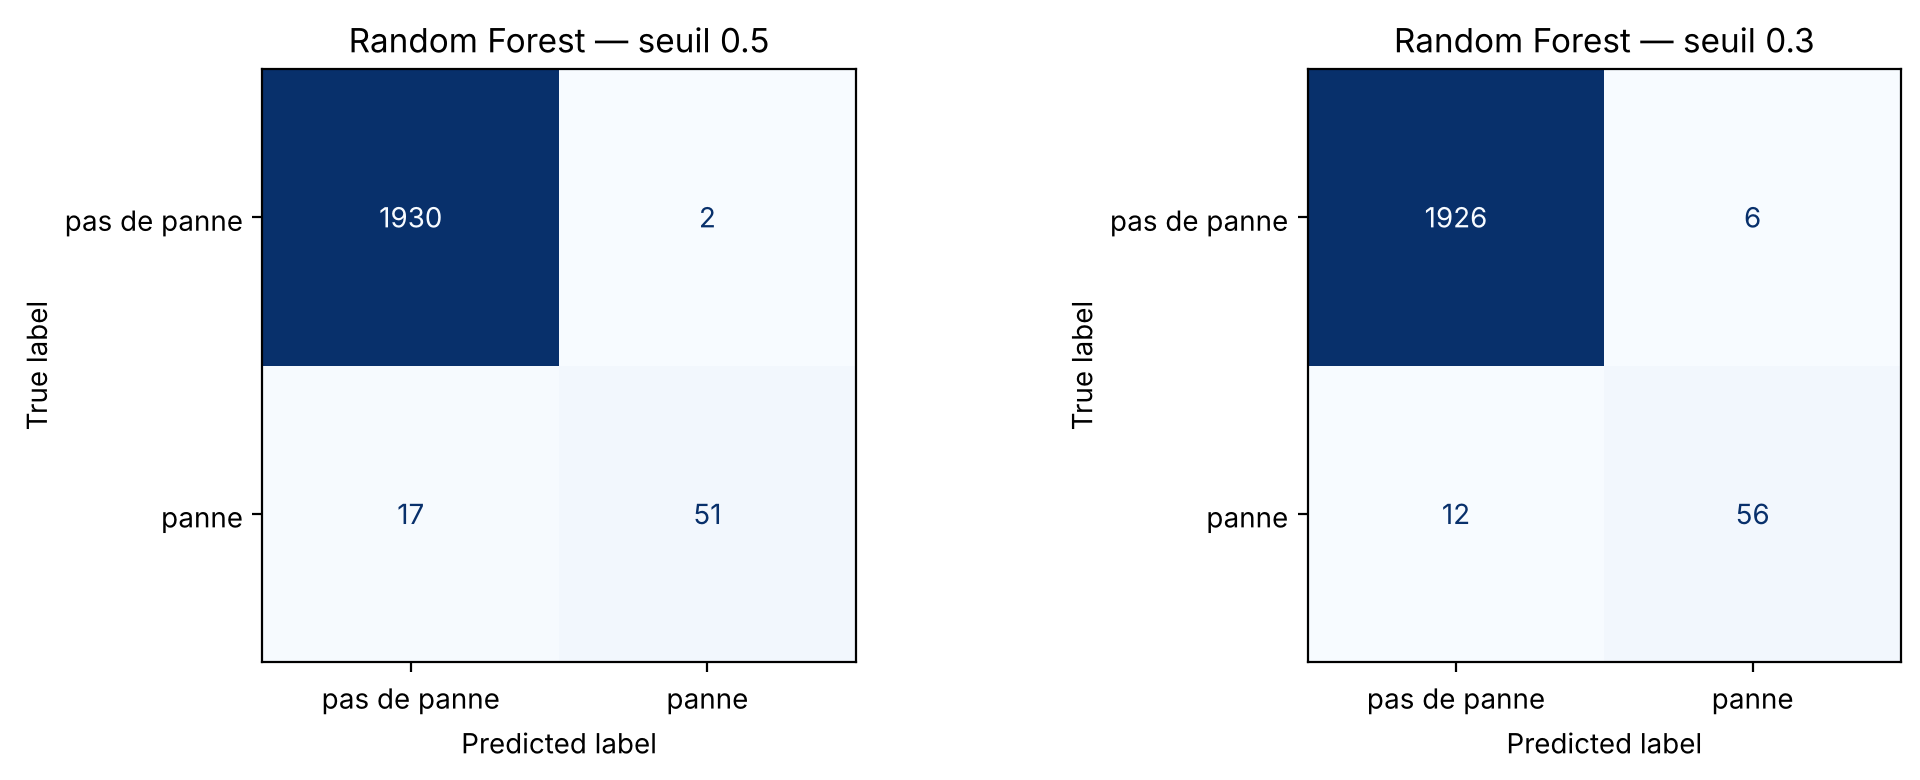

In [11]:
pred_test = (proba_test >= SEUIL).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s in zip(axes, [0.5, SEUIL]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba_test >= s).astype(int)),
                           display_labels=['pas de panne', 'panne']).plot(cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'Random Forest — seuil {s}')
plt.tight_layout(); plt.show()

**Résultats sur le jeu de test (2 000 mesures, 68 pannes).**
- Notre Random Forest au seuil 0,3 détecte **56 pannes sur 68 (rappel 0,82)** avec une précision de 0,90 et le meilleur F1 (0,86) de tous les cas testés. L'approche de référence n'en détecte que 42 : **14 pannes de plus** détectées.
- Le choix du seuil se confirme sur le test : passer de 0,5 à 0,3 détecte 5 pannes de plus (17 → 12 manquées) pour seulement 4 fausses alarmes supplémentaires (2 → 6).
- XGBoost manque une panne de moins (11) mais avec 10 fausses alarmes : notre Random Forest est plus précis à rappel quasi égal.

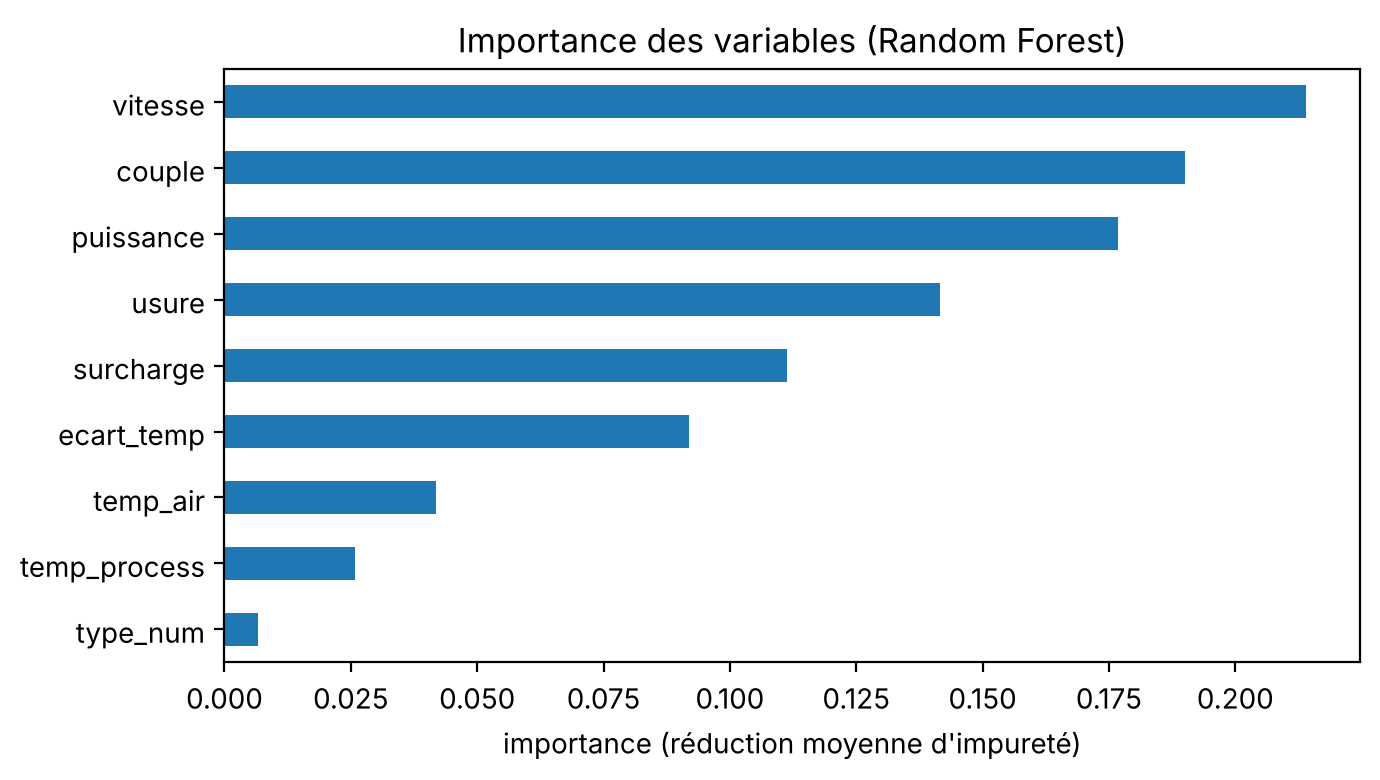

In [12]:
# Quelles variables comptent le plus pour le Random Forest ?
imp = pd.Series(rf.feature_importances_, index=entrees).sort_values()
imp.plot.barh(figsize=(7, 4), color='tab:blue'); plt.title('Importance des variables (Random Forest)')
plt.xlabel('importance (réduction moyenne d\'impureté)'); plt.tight_layout(); plt.show()

**Importance des variables.** Les variables les plus utiles sont la vitesse, le couple et la puissance (pannes de puissance et de surcharge), puis l'usure, la surcharge et l'écart de température. Les variables construites (`puissance`, `surcharge`, `ecart_temp`) arrivent toutes dans le haut du classement : elles résument en une seule grandeur physique ce que le modèle devrait sinon reconstruire par plusieurs coupures successives. Le type de produit (L, M, H) apporte très peu d'information.

### Analyse des cas d'échec

On regarde les pannes que le modèle n'a pas vues (faux négatifs) et les fausses alarmes, avec le type de panne réel.

In [13]:
test = df.loc[X_test.index].copy()
test['proba_panne'] = proba_test
test['prediction'] = pred_test

manquees = test[(test['panne'] == 1) & (test['prediction'] == 0)]
fausses_alarmes = test[(test['panne'] == 0) & (test['prediction'] == 1)]
print(f"Seuil {SEUIL} -> pannes manquées : {len(manquees)} | fausses alarmes : {len(fausses_alarmes)}")
print()
recap = pd.DataFrame({'pannes du test': test.loc[test['panne'] == 1, ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum(),
                      'manquées': manquees[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum()})
recap['taux de détection'] = (1 - recap['manquées'] / recap['pannes du test']).round(2)
print(recap)
manquees[['Type', 'temp_air', 'temp_process', 'ecart_temp', 'vitesse', 'couple', 'usure', 'proba_panne',
          'TWF', 'HDF', 'PWF', 'OSF', 'RNF']].round(3)

Seuil 0.3 -> pannes manquées : 12 | fausses alarmes : 6

     pannes du test  manquées  taux de détection
TWF              10         9               0.10
HDF              29         1               0.97
PWF              13         0               1.00
OSF              16         0               1.00
RNF               0         0                NaN


,Type,temp_air,temp_process,ecart_temp,vitesse,couple,usure,proba_panne,TWF,HDF,PWF,OSF,RNF
9174,L,297.8,308.9,11.1,1871,25.6,200,0.003,1,0,0,0,0
2671,M,299.7,309.3,9.6,1399,41.9,221,0.027,1,0,0,0,0
2864,H,300.6,309.4,8.8,1380,47.6,246,0.213,1,0,0,0,0
3695,L,302.2,311.3,9.1,1530,37.3,207,0.140,1,0,0,0,0
7087,L,300.6,310.3,9.7,1648,30.5,217,0.160,1,0,0,0,0
2941,M,300.7,309.6,8.9,1996,19.8,203,0.013,1,0,0,0,0
9015,L,297.2,308.1,10.9,1431,49.7,210,0.027,0,0,0,0,0
4778,H,303.6,312.2,8.6,1371,54.6,112,0.123,0,1,0,0,0
7849,M,300.3,311.7,11.4,1374,47.9,222,0.060,1,0,0,0,0
8506,L,298.4,309.6,11.2,1710,27.3,163,0.000,0,0,0,0,0


In [14]:
print("Fausses alarmes :")
fausses_alarmes[['Type', 'ecart_temp', 'vitesse', 'couple', 'usure', 'surcharge', 'proba_panne']].round(3)

Fausses alarmes :


,Type,ecart_temp,vitesse,couple,usure,surcharge,proba_panne
4231,L,8.6,1340,47.8,54,2581.2,0.847
3856,M,8.8,1330,58.6,201,11778.6,0.343
3794,M,8.6,1356,48.3,36,1738.8,0.883
8025,M,11.2,1422,50.7,219,11103.3,0.370
7677,L,11.1,1428,52.6,208,10940.8,0.333
6612,L,9.0,1222,70.0,62,4340.0,0.320


**Pourquoi ces pannes sont-elles manquées ?**
- **9 des 12 pannes manquées sont des TWF** (usure de l'outil) : seule 1 panne TWF sur 10 est détectée. Dans ce jeu, la panne TWF survient à un instant **aléatoire** quand l'usure est comprise entre environ 200 et 240 min. Le modèle voit donc des mesures identiques (même usure, conditions normales) qui tombent parfois en panne et parfois non : aucune variable instantanée ne permet de les distinguer. C'est une limite des données, pas seulement du modèle.
- **1 panne HDF** (mesure 4778) est manquée avec une probabilité de 0,12 : son écart de température vaut 8,6 K, exactement à la limite de la zone thermique.
- **2 pannes n'ont aucun mode renseigné** (mesures 9015 et 8506) : ce sont des anomalies d'étiquetage du jeu de données, impossibles à prédire.
- Les modes PWF et OSF, qui dépendent de règles physiques nettes (puissance, usure × couple), sont **tous détectés**.

**Fausses alarmes (6).** Elles concernent soit des outils très usés (plus de 200 min) avec une forte surcharge, soit des mesures à la limite thermique (écart de 8,6 à 9 K, basse vitesse) ou à très fort couple (70 Nm). Ce sont des situations objectivement à risque : une inspection y reste justifiée.

**Pistes d'amélioration.**
- Pour les TWF, une variable instantanée ne suffit pas. En pratique, on remplacerait l'outil de façon **préventive** au-delà d'environ 200 min : c'est exactement ce que fait la règle R5 du système flou (outil très usé → priorité au moins moyenne).
- Ajouter un indicateur binaire « usure > 200 min » ou entraîner un modèle par mode de panne.
- Avec des données temporelles réelles (historique de l'outil, vibrations, effort de coupe), la dégradation progressive deviendrait observable.

### Temps d'inférence

In [15]:
def chrono(fonction, n_rep=5):
    t0 = time.perf_counter()
    for _ in range(n_rep):
        fonction()
    return (time.perf_counter() - t0) / n_rep

t_rf  = chrono(lambda: rf.predict_proba(X_test[entrees])) / len(X_test)
t_xgb = chrono(lambda: xgb.predict_proba(X_test[entrees])) / len(X_test)
une_mesure = X_test[entrees].iloc[[0]]
t_rf_1 = chrono(lambda: rf.predict_proba(une_mesure), 20)
print(f"Random Forest : {t_rf*1e6:.1f} µs par mesure (lot de {len(X_test)}) | {t_rf_1*1e3:.1f} ms pour une mesure seule")
print(f"XGBoost       : {t_xgb*1e6:.1f} µs par mesure (lot de {len(X_test)})")

Random Forest : 31.9 µs par mesure (lot de 2000) | 48.2 ms pour une mesure seule
XGBoost       : 2.4 µs par mesure (lot de 2000)


**Temps d'inférence.** Par lot, le Random Forest prédit en quelques dizaines de microsecondes par mesure et XGBoost encore plus vite. Pour une mesure seule, le temps est dominé par le coût fixe d'appel (quelques dizaines de millisecondes, dont la répartition sur plusieurs cœurs avec `n_jobs=-1`). Une machine-outil envoie une mesure toutes les secondes au mieux : les deux modèles sont **largement compatibles avec un fonctionnement en temps réel**.

## 7. Système flou : priorité de maintenance

Le modèle ML donne une probabilité. Le système flou la combine avec deux grandeurs techniques pour produire une décision lisible par un opérateur.

| | Variable | Univers | Termes |
|---|---|---|---|
| Entrée 1 | Probabilité de panne (sortie du Random Forest) | 0 à 1 | faible, moyenne, élevée |
| Entrée 2 | Usure de l'outil | 0 à 260 min | faible, moyenne, élevée |
| Entrée 3 | Échauffement = 12 − écart de température | 0 à 5 K | normal, élevé |
| Sortie | Priorité de maintenance | 0 à 10 | faible, moyenne, urgente |

**Définition de l'échauffement.** Dans ce jeu de données, la panne thermique (HDF) arrive quand l'écart entre la température du procédé et celle de l'air est **faible** : la chaleur produite par la coupe s'évacue mal. On définit donc `échauffement = 12 − écart` (en K), pour qu'une grande valeur signifie un risque thermique élevé. La partie 2 confirme ce sens : toutes les pannes HDF ont un écart inférieur à 8,6 K, c'est-à-dire un échauffement supérieur à 3,4 K.

**Méthode de Mamdani** (choix par défaut de scikit-fuzzy) : ET = minimum, agrégation des règles = maximum, défuzzification par **centre de gravité**.

**Justification des fonctions d'appartenance.**
- **Probabilité** : « faible » en dessous de 0,1 (le modèle est rassurant), « moyenne » culmine à 0,35, au niveau du **seuil de décision retenu** (0,3, partie 5), et « élevée » commence à 0,4 pour être totale au-delà de 0,65. « Moyenne » couvre donc la zone de doute de 0,1 à 0,6.
- **Usure** : « élevée » à partir de 170 min et pleinement à 210 min, car le taux de panne explose au-delà de 190 min et les pannes TWF commencent à 198 min. « Faible » jusqu'à 60 min (outil neuf), avec des recouvrements pour éviter les sauts de décision.
- **Échauffement** : la transition « normal / élevé » se fait entre 2,8 et 3,6 K, autour de 3,4 K (écart de 8,6 K) où apparaissent les pannes HDF.
- **Priorité** : trois termes qui se recouvrent, pour une sortie progressive entre 0 et 10.

Triangles et trapèzes ont été choisis car ils sont simples à expliquer à un opérateur et à régler.

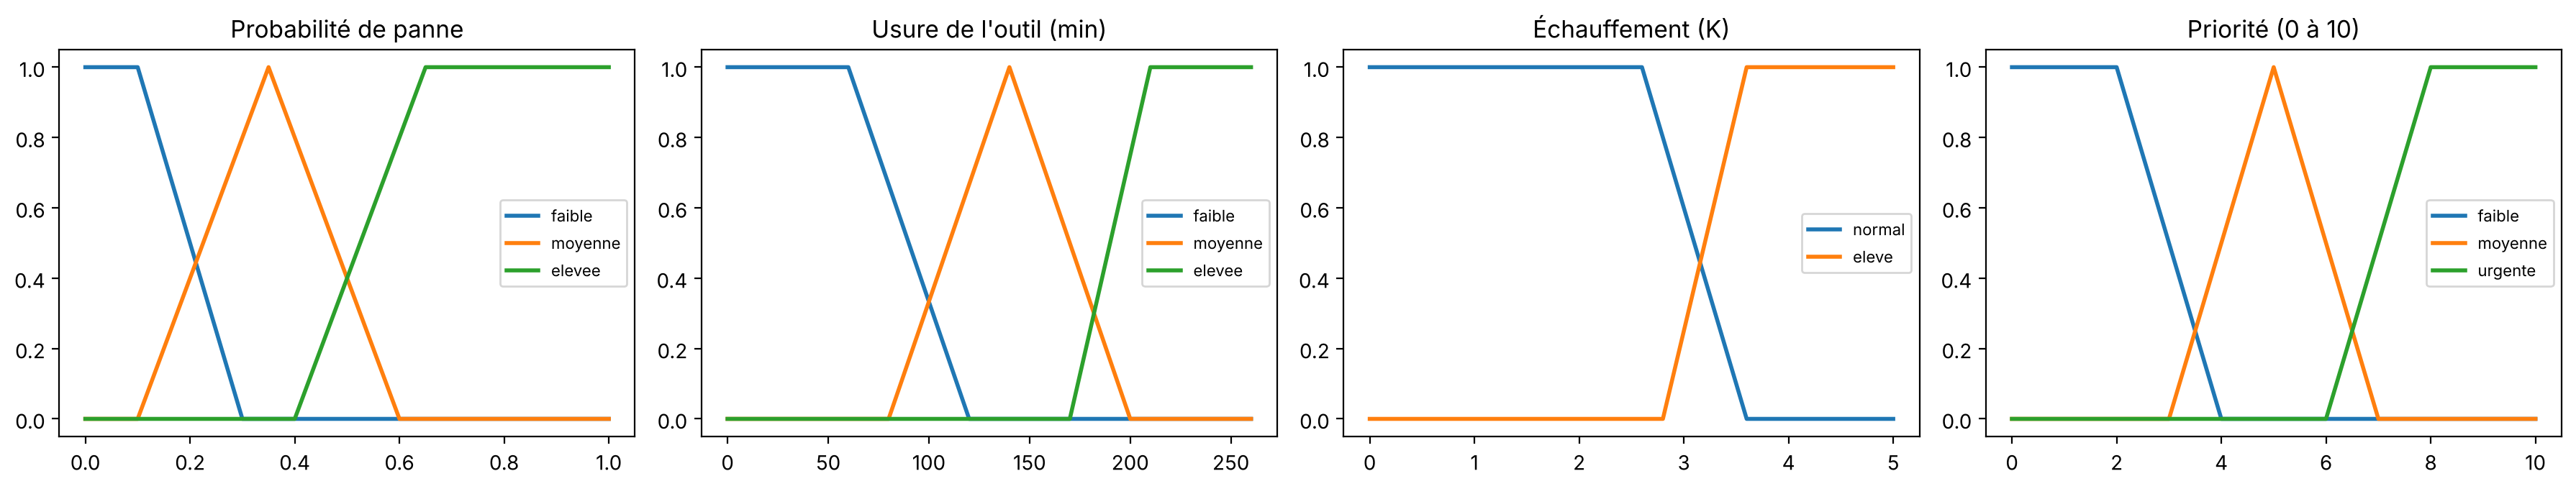

In [16]:
proba  = ctrl.Antecedent(np.linspace(0, 1, 101),  'proba')
usure  = ctrl.Antecedent(np.arange(0, 261, 1),    'usure')
echauf = ctrl.Antecedent(np.linspace(0, 5, 101),  'echauffement')
prio   = ctrl.Consequent(np.linspace(0, 10, 101), 'priorite')   # défuzzification par centre de gravité

proba['faible']  = fuzz.trapmf(proba.universe, [0, 0, 0.10, 0.30])
proba['moyenne'] = fuzz.trimf(proba.universe,  [0.10, 0.35, 0.60])
proba['elevee']  = fuzz.trapmf(proba.universe, [0.40, 0.65, 1, 1])

usure['faible']  = fuzz.trapmf(usure.universe, [0, 0, 60, 120])
usure['moyenne'] = fuzz.trimf(usure.universe,  [80, 140, 200])
usure['elevee']  = fuzz.trapmf(usure.universe, [170, 210, 260, 260])

echauf['normal'] = fuzz.trapmf(echauf.universe, [0, 0, 2.6, 3.6])    # écart de température > 8,4 K environ
echauf['eleve']  = fuzz.trapmf(echauf.universe, [2.8, 3.6, 5, 5])    # écart de température < 9,2 K environ

prio['faible']  = fuzz.trapmf(prio.universe, [0, 0, 2, 4])
prio['moyenne'] = fuzz.trimf(prio.universe,  [3, 5, 7])
prio['urgente'] = fuzz.trapmf(prio.universe, [6, 8, 10, 10])

fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, variable, titre in zip(axes, (proba, usure, echauf, prio),
                               ('Probabilité de panne', "Usure de l'outil (min)", 'Échauffement (K)', 'Priorité (0 à 10)')):
    for terme, fa in variable.terms.items():
        ax.plot(variable.universe, fa.mf, label=terme, lw=2)
    ax.set_title(titre); ax.set_ylim(-0.05, 1.05); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Base de règles (10 règles)

| Règle | SI | ALORS priorité | Justification mécanique |
|---|---|---|---|
| R1 | probabilité élevée | urgente | Le modèle est presque sûr de la panne : on arrête et on intervient. |
| R2 | probabilité moyenne ET usure élevée | urgente | Doute du modèle sur un outil en fin de vie : le risque de casse est réel. |
| R3 | probabilité moyenne ET usure moyenne | moyenne | Doute sans facteur aggravant : on planifie une inspection. |
| R4 | probabilité moyenne ET usure faible | moyenne | Outil neuf, mais le modèle signale un risque (puissance, surcharge) : inspection. |
| R5 | probabilité faible ET usure élevée | moyenne | Même si le modèle est rassurant, un outil en fin de vie doit être changé (pannes TWF imprévisibles). |
| R6 | probabilité faible ET usure moyenne | faible | Fonctionnement normal. |
| R7 | probabilité faible ET usure faible | faible | Machine saine, outil neuf. |
| R8 | probabilité moyenne ET échauffement élevé | urgente | Doute du modèle + mauvaise évacuation de la chaleur : risque de panne thermique. |
| R9 | probabilité faible ET échauffement élevé | moyenne | Le refroidissement est à surveiller même sans alerte du modèle. |
| R10 | usure élevée ET échauffement élevé | urgente | Outil usé qui chauffe : combinaison la plus dangereuse pour l'outil et la pièce. |

Le système ne contient volontairement aucune règle qui **baisse** la priorité quand le modèle est inquiet : la sortie du ML reste prioritaire, les grandeurs techniques ne font qu'**ajouter** de la prudence.

In [17]:
regles = [
    # R1. Le modèle est presque sûr de la panne : on intervient tout de suite.
    ctrl.Rule(proba['elevee'], prio['urgente']),
    # R2 à R4. Probabilité moyenne : la décision dépend de l'état de l'outil.
    ctrl.Rule(proba['moyenne'] & usure['elevee'],  prio['urgente']),
    ctrl.Rule(proba['moyenne'] & usure['moyenne'], prio['moyenne']),
    ctrl.Rule(proba['moyenne'] & usure['faible'],  prio['moyenne']),
    # R5 à R7. Probabilité faible : un outil très usé doit quand même être planifié.
    ctrl.Rule(proba['faible'] & usure['elevee'],  prio['moyenne']),
    ctrl.Rule(proba['faible'] & usure['moyenne'], prio['faible']),
    ctrl.Rule(proba['faible'] & usure['faible'],  prio['faible']),
    # R8 à R10. L'échauffement aggrave la situation.
    ctrl.Rule(proba['moyenne'] & echauf['eleve'], prio['urgente']),
    ctrl.Rule(proba['faible'] & echauf['eleve'],  prio['moyenne']),
    ctrl.Rule(usure['elevee'] & echauf['eleve'],  prio['urgente']),
]
systeme = ctrl.ControlSystem(regles)
simulateur = ctrl.ControlSystemSimulation(systeme)

def priorite_floue(p, u, e):
    """Renvoie la priorité de maintenance (0 à 10) pour une mesure."""
    simulateur.input['proba'] = float(np.clip(p, 0, 1))
    simulateur.input['usure'] = float(np.clip(u, 0, 260))
    simulateur.input['echauffement'] = float(np.clip(e, 0, 5))
    simulateur.compute()
    return simulateur.output['priorite']

def etiquette(score):
    # Lecture de la sortie : les seuils 3,5 et 6,5 correspondent aux croisements des termes de sortie
    return 'faible' if score < 3.5 else ('moyenne' if score < 6.5 else 'urgente')

# Situations types pour vérifier que le système réagit comme on l'attend
cas = [('Machine saine, outil neuf',            0.02,  30, 10.5),
       ('Doute du modèle, outil à mi-vie',      0.30, 150,  9.5),
       ('Modèle rassurant mais outil en fin de vie et chaud', 0.05, 220,  8.3),
       ('Modèle presque sûr de la panne',       0.85,  60, 10.0)]
for nom, p, u, ecart in cas:
    s = priorite_floue(p, u, 12 - ecart)
    print(f"{nom:<52} proba={p:.2f} usure={u:>3} min écart={ecart:>4} K -> priorité {s:.1f}/10 ({etiquette(s)})")

Machine saine, outil neuf                            proba=0.02 usure= 30 min écart=10.5 K -> priorité 1.6/10 (faible)
Doute du modèle, outil à mi-vie                      proba=0.30 usure=150 min écart= 9.5 K -> priorité 5.0/10 (moyenne)
Modèle rassurant mais outil en fin de vie et chaud   proba=0.05 usure=220 min écart= 8.3 K -> priorité 7.1/10 (urgente)
Modèle presque sûr de la panne                       proba=0.85 usure= 60 min écart=10.0 K -> priorité 8.4/10 (urgente)


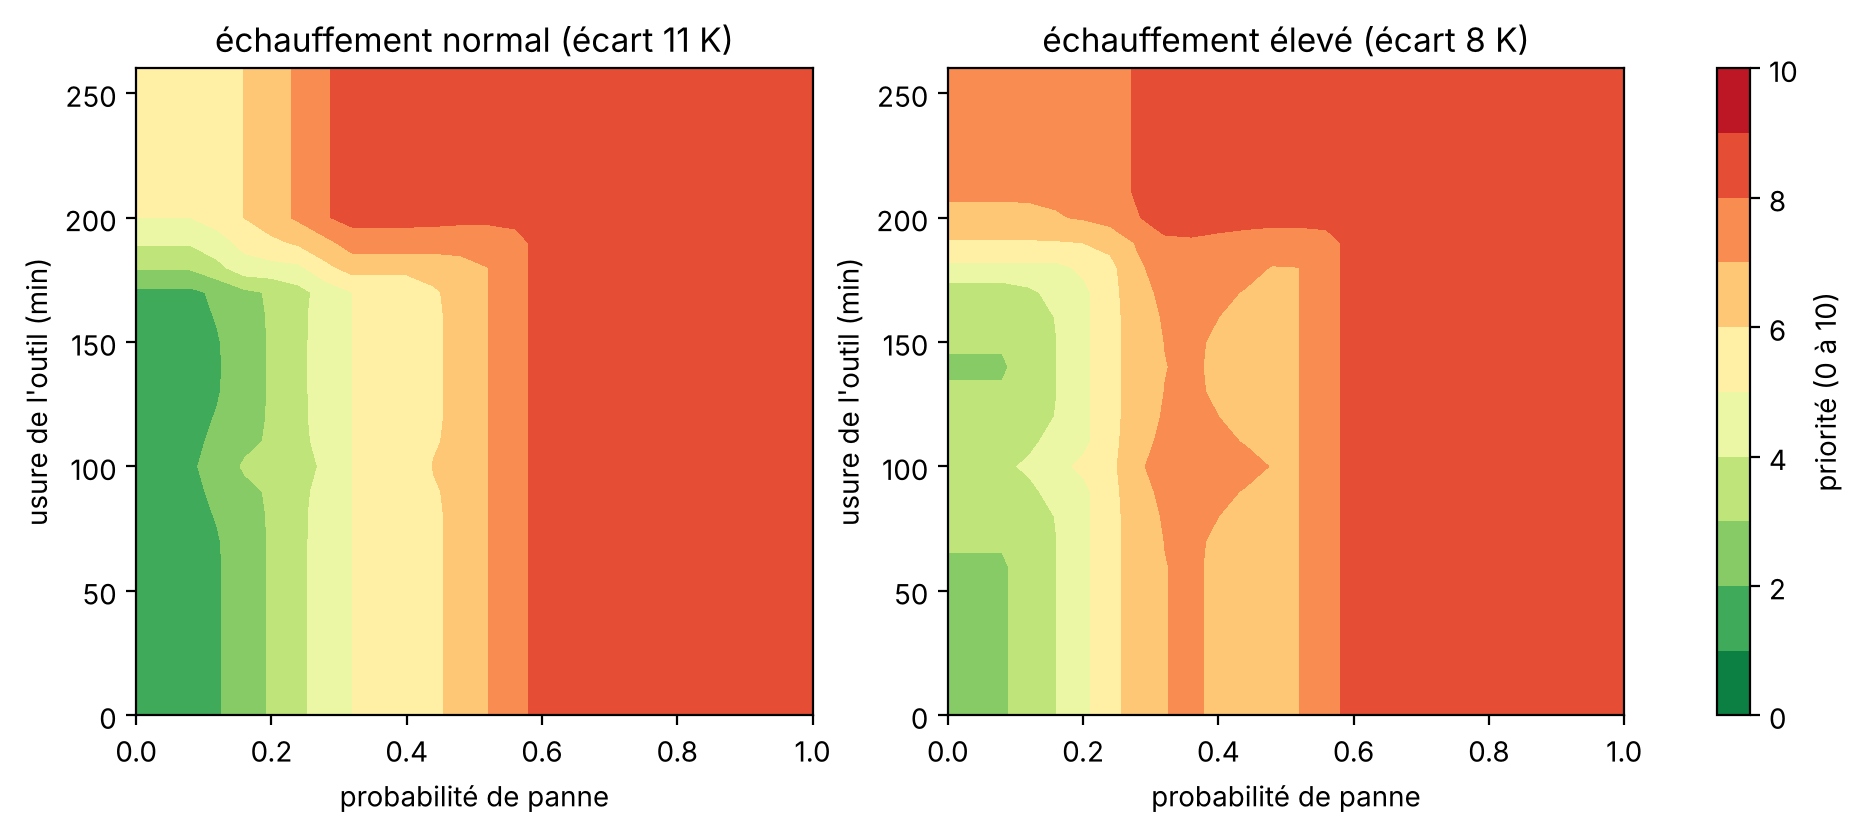

In [18]:
# Surface de décision : priorité en fonction de la probabilité et de l'usure (échauffement normal puis élevé)
P, U = np.meshgrid(np.linspace(0, 1, 26), np.linspace(0, 260, 27))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, e, titre in zip(axes, [1.0, 4.0], ['échauffement normal (écart 11 K)', 'échauffement élevé (écart 8 K)']):
    Z = np.vectorize(lambda p, u: priorite_floue(p, u, e))(P, U)
    im = ax.contourf(P, U, Z, levels=np.linspace(0, 10, 11), cmap='RdYlGn_r')
    ax.set_xlabel('probabilité de panne'); ax.set_ylabel("usure de l'outil (min)"); ax.set_title(titre)
fig.colorbar(im, ax=axes, label='priorité (0 à 10)')
plt.show()

**Lecture de la surface de décision.** La priorité augmente de manière continue avec la probabilité de panne : au-delà de 0,6, elle est toujours urgente. À probabilité faible, la priorité ne reste « faible » (vert) que si l'outil a moins d'environ 170 min d'usure : au-delà, elle passe en « moyenne » (règle R5). Quand l'échauffement est élevé (figure de droite), toute la surface est décalée vers le haut : la zone verte rétrécit et la zone urgente commence dès 0,3 de probabilité pour un outil usé. Il n'y a pas de saut brutal, contrairement à un système à seuils fixes : c'est l'intérêt de la logique floue.

### Application à toutes les mesures de test

In [19]:
test['echauffement'] = 12 - test['ecart_temp']

t0 = time.perf_counter()
test['priorite'] = [priorite_floue(p, u, e)
                    for p, u, e in zip(test['proba_panne'], test['usure'], test['echauffement'])]
t_flou = (time.perf_counter() - t0) / len(test)
test['priorite_label'] = test['priorite'].apply(etiquette)
print(f"Système flou : {t_flou*1e3:.2f} ms par mesure")

# Les vraies pannes reçoivent-elles une priorité élevée ?
tableau = pd.crosstab(test['priorite_label'], test['panne'].map({0: 'pas de panne', 1: 'panne'}))
tableau = tableau.reindex(['faible', 'moyenne', 'urgente']).fillna(0).astype(int)
tableau['part des pannes (%)'] = (100 * tableau['panne'] / tableau['panne'].sum()).round(1)
tableau

Système flou : 1.78 ms par mesure


panne,panne,pas de panne,part des pannes (%)
priorite_label,,,
faible,1,1615,1.5
moyenne,9,284,13.2
urgente,58,33,85.3


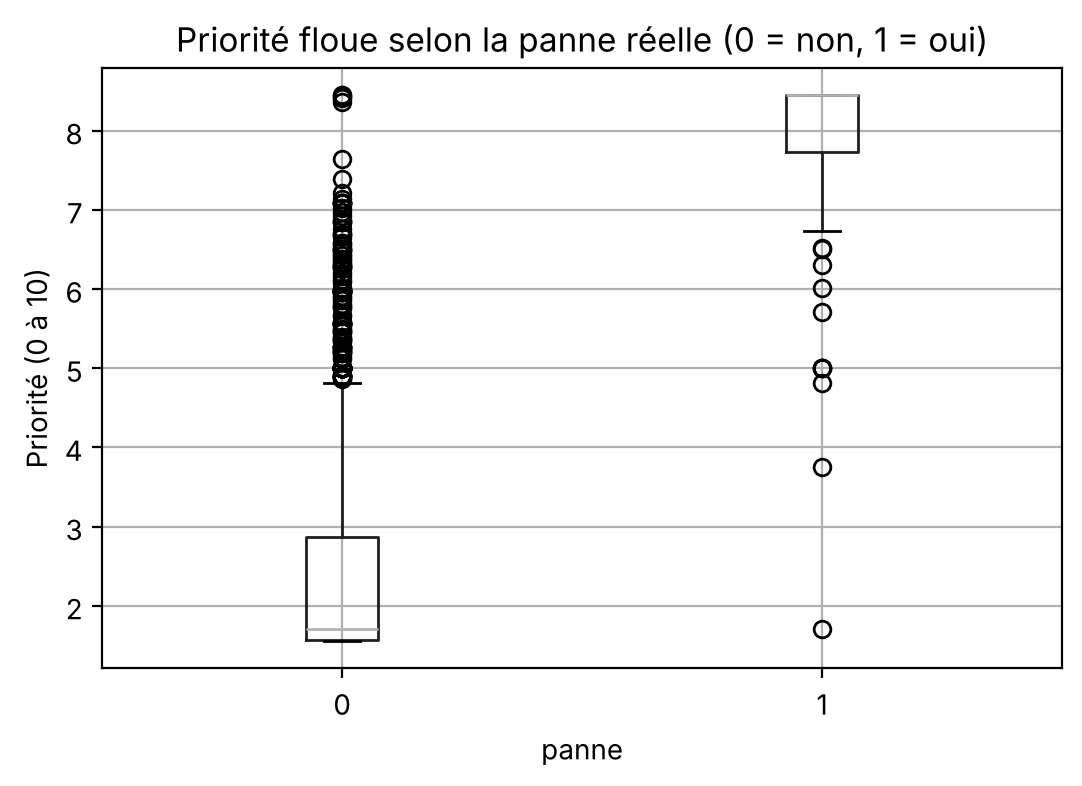

,temp_air,temp_process,vitesse,couple,usure,proba_panne,priorite,TWF,HDF,PWF,OSF,RNF
8506,298.4,309.6,1710,27.3,163,0.0,1.71,0,0,0,0,0


In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
test.boxplot(column='priorite', by='panne', ax=ax)
plt.suptitle(''); ax.set_title('Priorité floue selon la panne réelle (0 = non, 1 = oui)')
ax.set_ylabel('Priorité (0 à 10)'); plt.show()

# Les vraies pannes classées « faible » : ce sont les cas d'échec du système complet
test[(test['panne'] == 1) & (test['priorite_label'] == 'faible')][
    ['temp_air', 'temp_process', 'vitesse', 'couple', 'usure', 'proba_panne', 'priorite',
     'TWF', 'HDF', 'PWF', 'OSF', 'RNF']].round(3)

**Résultats du système complet sur le jeu de test.**
- **58 des 68 pannes (85 %) reçoivent la priorité « urgente »**, 9 la priorité « moyenne », et **une seule** la priorité « faible ». Le système flou rattrape donc une partie des pannes manquées par le modèle seul : les pannes TWF manquées concernent toutes des outils à plus de 198 min, que les règles sur l'usure font remonter au moins en priorité moyenne.
- Sur 1 932 mesures saines, 1 615 (84 %) restent en priorité faible et seulement 33 passent en urgente : l'opérateur n'est pas noyé sous les alertes. Les alertes injustifiées correspondent surtout à des outils en fin de vie qu'il est raisonnable de remplacer.
- **La seule panne classée « faible »** (mesure 8506) est une panne sans mode renseigné, avec une probabilité nulle et un outil à 163 min : aucune grandeur ne la signalait. C'est une limite du jeu de données plutôt que du système.
- Le système flou prend quelques millisecondes par mesure, nettement plus que le Random Forest par lot, mais largement suffisant pour de la maintenance (une décision par seconde suffit).

## 8. Conclusion

- **Modèle ML.** Le Random Forest avec variables physiques et pondération des classes obtient le meilleur compromis (F1 de 0,85 en validation croisée). Au seuil retenu, il détecte **56 des 68 pannes du test (rappel 0,82, précision 0,90)**, contre 42 pour l'approche des notebooks publics. XGBoost obtient un rappel proche mais une précision plus faible.
- **Seuil.** Le seuil 0,3, choisi par validation croisée avec le F2-score, traduit le fait qu'une panne manquée coûte plus cher qu'une fausse alarme ; le jeu de test confirme ce choix (5 pannes de plus détectées pour 4 fausses alarmes).
- **Système flou.** Il transforme une probabilité abstraite en une priorité compréhensible et ajoute la connaissance du mécanicien (usure, échauffement) : **85 % des pannes du test sont classées urgentes et une seule est classée faible**, tandis que 84 % des mesures saines restent en priorité faible.
- **Limites.** Les pannes par usure de l'outil (TWF) sont aléatoires dans ce jeu et restent mal prédites par le modèle seul ; seul un remplacement préventif de l'outil (règle R5) les couvre. Le jeu est synthétique : sur une vraie machine, il faudrait valider les fonctions d'appartenance avec les opérateurs et utiliser l'historique de chaque outil.
- **Perspectives.** Prédire le type de panne, comparer le système flou à des seuils fixes, étudier la sensibilité aux fonctions d'appartenance et utiliser des données temporelles.